TARIK TUNA TAŞALTI

In [14]:
my_packages <- c("ggplot2", "dplyr", "readr", "stringr", "ggbeeswarm", "shiny","patchwork")

for (pkg in my_packages) {
  if (!require(pkg, character.only = TRUE)) {
    install.packages(pkg)
    library(pkg, character.only = TRUE)
  }
}


Bu kısımda kodun ilerleyen kısmında kullanılacak kütüphaneler tanımlanır.

In [15]:
team_palette <- c(
  "Mercedes" = "#27F4D2",
  "Ferrari" = "#E8002D",
  "Red Bull Racing" = "#3671C6",
  "McLaren" = "#FF8700",
  "RB" = "#6692FF",
  "Alpine" = "#FF87BC",
  "Aston Martin" = "#229971",
  "Williams" = "#64C4FF",
  "Kick Sauber" = "#52E252",
  "Haas F1 Team" = "#B6BABD"
)
COMPOUND_COLORS <- c(
  'HARD' = '#f0f0ec',
  'INTERMEDIATE' = '#43b02a',
  'MEDIUM' = '#ffd12e',
  'SOFT' = '#da291c',
  'TEST-UNKNOWN' = '#434649',
  'UNKNOWN' = '#00ffff',
  'WET' = '#0067ad'
)


# Lap timesı saniyeye dönüştürme fonksiyonu
convert_to_time <- function(time_str) {
  time_str <- str_remove(time_str, "0 days ")
  hms <- str_split(time_str, "[:.]")[[1]]
  total_seconds <- as.numeric(hms[2]) * 60 + as.numeric(hms[3]) + as.numeric(hms[4]) / 1000000
  return(total_seconds)
}

Bu kısımda takım renkleri, lastik renkleri ve time yapısını saniye türünde değişkene çeviren fonksiyonlar tanımlanmıştır.

Kod boyunca plot_strategy ve plot_positions adlı fonksiyonlara input olarak bütün tur verileri verilirken create_boxplot, create_swarm_violin_plot, plot_driver_laptimes fonksiyonlarında yarışta atılan en hızlı turun %107'sine kadar olan tur zamanlarının olduğu veriler kullanılmıştır. Bunun sebebi, yarışlardaki kazalardan, pit-stoplardan kaynaklı yaşanan yarış temposunu yansıtmayan verilerin grafiğin detay seviyesini düşürmesidir. 

In [16]:
create_boxplot <- function(data, title, subtitle, x_label, y_label, grouping_var, show_legend = FALSE) {
  data <- data %>%
    mutate(LapTime_sec = sapply(LapTime, function(x) convert_to_time(x))) %>%
    filter(!is.na(LapTime_sec) & is.finite(LapTime_sec))
  
  order_var <- data %>%
    group_by(!!grouping_var) %>%
    summarize(median_lap_time = median(LapTime_sec, na.rm = TRUE)) %>%
    arrange(desc(median_lap_time)) %>%
    pull(!!grouping_var)
  
  data <- data %>%
    mutate(!!quo_name(grouping_var) := factor(!!grouping_var, levels = order_var))
  
  plot <- ggplot(data, aes(x = !!grouping_var, y = LapTime_sec, fill = Team)) +
    geom_boxplot(
      color = "black", 
      outlier.colour = "red", 
      outlier.shape = 16,
      outlier.size = 2,
      fatten = 1.5,
      linewidth = 0.5
    ) +
    scale_fill_manual(values = team_palette) +
    #scale_x_continuous(breaks = seq(1, max(data$LapNumber), by = 1)) +
    
    theme_minimal() + # Added + sign here
    
    theme(
      legend.position = "right",
      panel.background = element_rect(fill = "#434345"),
      plot.background = element_rect(fill = "white"),
      legend.background = element_rect(fill = "white", color = "black"),
      legend.text = element_text(color = "black"),
      legend.title = element_text(color = "black"),
      axis.text = element_text(color = "black"),
      axis.title = element_text(color = "black"),
      panel.grid.major = element_blank(),
      panel.grid.minor = element_blank(),
      plot.title = element_text(color = "black"),
      plot.subtitle = element_text(color = "black"),
      plot.caption = element_text(color = "black")
    )  +
    labs(
      title = title,
      x = x_label,
      y = y_label,
      subtitle = subtitle,
      caption = "Tarık Tuna Taşaltı"
    ) +
    coord_flip()
  
  return(plot)
}


kodun bu kısmında, boxplotları oluşturan fonksiyon tanımlanmıştır. Fonksiyona input olarak sürücü bazlı mı yoksa takım bazlı mı görüntüleme yapılacağı gönderilir. Buna göre her ikisi için de gerekli grafikler ortaya konulur.

In [17]:
# Bee swarm chart ve violin plot oluştur fonksiyonu
create_swarm_violin_plot <- function(data, title,subtitle, x_label, y_label, grouping_var, top_n_drivers = TRUE) {
  data <- data %>%
    mutate(LapTime_sec = sapply(LapTime, function(x) convert_to_time(x))) %>%
    filter(!is.na(LapTime_sec) & is.finite(LapTime_sec))
  
  order_var <- data %>%
    group_by(!!grouping_var) %>%
    summarize(median_lap_time = median(LapTime_sec, na.rm = TRUE)) %>%
    arrange(desc(median_lap_time)) %>%
    pull(!!grouping_var)
  
  data <- data %>%
    mutate(!!quo_name(grouping_var) := factor(!!grouping_var, levels = order_var))
  
  # İlk 10 veya son 10 sürücüyü filtrele
  if (top_n_drivers) {
    filtered_data <- data %>%
      group_by(!!grouping_var) %>%
      summarize(median_lap_time = median(LapTime_sec, na.rm = TRUE)) %>%
      arrange(desc(median_lap_time)) %>%
      top_n(-10, wt = median_lap_time) %>%
      inner_join(data, by = quo_name(grouping_var))
  } else {
    filtered_data <- data %>%
      group_by(!!grouping_var) %>%
      summarize(median_lap_time = median(LapTime_sec, na.rm = TRUE)) %>%
      arrange(desc(median_lap_time)) %>%
      top_n(10, wt = median_lap_time) %>%
      inner_join(data, by = quo_name(grouping_var))
  }
  
  plot <- ggplot(filtered_data, aes(x = !!grouping_var, y = LapTime_sec)) +
    geom_violin(
      aes(fill = Team),
      alpha = 0.5,
      trim = FALSE
    ) +
    geom_beeswarm(
      aes(color = Compound),
      size = 3
    ) +
    scale_fill_manual(values = team_palette) +
    scale_color_manual(values = COMPOUND_COLORS) +
    scale_y_continuous(breaks = seq(floor(min(filtered_data$LapTime_sec)), ceiling(max(filtered_data$LapTime_sec)), by = 1)) + # Y eksenini 1 saniye farkla göster
    theme_minimal() +
        theme(panel.background = element_rect(fill = "#434345"),
          plot.background = element_rect(fill = "white"),
          legend.background = element_rect(fill = "white",color="black"),
          legend.text = element_text(color = "black"),
          legend.title = element_text(color = "black"),
          axis.text = element_text(color = "black"),
          axis.title = element_text(color = "black"),
          panel.grid.major = element_blank(), 
          panel.grid.minor = element_blank(),
          plot.title = element_text(color = "black"),
          plot.subtitle = element_text(color = "black"),
          plot.caption = element_text(color = "black")) +
    labs(
      title = title,
      x = x_label,
      y = y_label,
      subtitle = subtitle,
      caption = "Tarık Tuna Taşaltı"
    )+
    coord_flip()
  
  return(plot)
}


Bu fonsiyon boxplot'a çok benzer yorum yapılabilecek bir bir grafik ortaya koymaktadır. Beeswarm kullanılarak, hangi tur sürelerinde yığılma olduğu nokta nokta gösterilir. Beeswarm sayesinde hangi tur süresinde hangi compound kullanıldığı da renklendirildiği için gözükmektedir. Violinplot kullanılarak ise bu yoğunluk olan noktaları kaplayan bir grafik elde edilir. Burada kullanılan renk sayesinde ise pilotun hangi takıma ait olduğu gözükmektedir.

In [18]:
plot_positions <- function(data, subtitle) {
  # Veri setindeki takımların renk paletindeki değerlerini eşleştir
  data$Color <- team_palette[as.character(data$Team)]
  
  # Renk paletini güncelle: Aynı takıma ait birinci sürücü ve ikinci sürücünün renklerini ayarla
  for (team in unique(data$Team)) {
    team_drivers <- unique(data$Driver[data$Team == team])
    if (length(team_drivers) == 2) {  # Eğer takımda iki sürücü varsa
      base_color <- team_palette[team]
      base_rgb <- col2rgb(base_color)  # Hex renk kodunu RGB kodlarına dönüştür
      
      # Renkleri 255 ile sınırla
      adjusted_rgb1 <- pmin(pmax(base_rgb - 8, 0), 255)
      adjusted_rgb2 <- pmin(pmax(base_rgb + 8, 0), 255)
      
      team_palette[team_drivers[1]] <- rgb(adjusted_rgb1[1], adjusted_rgb1[2], adjusted_rgb1[3], maxColorValue = 255)
      team_palette[team_drivers[2]] <- rgb(adjusted_rgb2[1], adjusted_rgb2[2], adjusted_rgb2[3], maxColorValue = 255)
    }
  }

  # Veri setindeki sürücü renklerini güncelle
  data$Color <- team_palette[data$Driver]

  # Y ekseni için pozisyonları tersine çevir
  max_position <- max(data$Position, na.rm = TRUE)
  data$AdjustedPosition <- max_position - data$Position + 1

  # Veriyi sırala: sürücü ve tur numarası
  data <- data %>% arrange(Driver, LapNumber)
  
  # Ensure that LapNumber and AdjustedPosition have finite values
  data <- data %>%
    filter(is.finite(LapNumber) & is.finite(AdjustedPosition))
  
  p <- ggplot(data, aes(x = LapNumber, y = AdjustedPosition, color = Driver, group = Driver)) +
    geom_line(size = 1) +
    scale_color_manual(values = team_palette) +
    labs(x = "Lap", y = "Position", title = "Position Change", subtitle = subtitle, caption = "Tarık Tuna Taşaltı") +
    theme_minimal() +
    scale_y_continuous(limits = c(1, max_position), breaks = seq(1, max_position, by = 1), labels = seq(max_position, 1, by = -1)) +
    scale_x_continuous(limits = c(1, max(data$LapNumber, na.rm = TRUE)), breaks = seq(0, max(data$LapNumber, na.rm = TRUE), by = 5), expand = c(0, 0)) +
    theme(
      legend.position = "right",
      panel.background = element_rect(fill = "#434345"),
      plot.background = element_rect(fill = "white"),
      legend.background = element_rect(fill = "white", color = "black"),
      legend.text = element_text(color = "black"),
      legend.title = element_text(color = "black"),
      axis.text = element_text(color = "black"),
      axis.title = element_text(color = "black"),
      plot.title = element_text(color = "black"),
      plot.subtitle = element_text(color = "black"),
      plot.caption = element_text(color = "black"),
      panel.grid.major.x = element_line(color = alpha("gray", 0.6), linetype = "dotted"),  # Ana dikey ızgara çizgilerini ayarla
      panel.grid.minor.x = element_line(color = alpha("gray", 0.6), linetype = "dotted"),  # İkincil dikey ızgara çizgilerini ayarla
      panel.grid.major.y = element_blank(),  # Ana yatay ızgara çizgilerini kaldır
      panel.grid.minor.y = element_blank()  # İkincil yatay ızgara çizgilerini kaldır
    ) +
    guides(color = guide_legend(title = "Drivers"))

  return(p)
}


Bu kod bloğu kullanılarak öncelikle, her pilota ayrı renkt ataması yapılmaktadır. Bu sayede, aynı takıma ait pilotlar farklı renklerle ayrışmaktadır. Sonrasında her tur başına hangi pilotun hangi sırada olduğu görüntüleyen bir grafik elde edilmektedir.

In [19]:
plot_strategy <- function(data, subtitle) {
  # Get unique drivers
  drivers <- unique(data$Driver)
  
  # Create a dataframe to store stint information
  stints <- data %>%
    group_by(Driver, Stint, Compound) %>%
    summarize(StintLength = n(), .groups = "drop") # Avoid grouping warning
  
  # Plot strategies for each driver
  ggplot(stints, aes(y = factor(Driver, levels = rev(drivers)), x = StintLength, fill = Compound)) +
    geom_bar(stat = "identity",color=black) +
    scale_fill_manual(values = COMPOUND_COLORS) +
    theme(panel.background = element_rect(fill = "#434345"),
          plot.background = element_rect(fill = "white"),
          legend.background = element_rect(fill = "white",color="black"),
          legend.text = element_text(color = "black"),
          legend.title = element_text(color = "black"),
          axis.text = element_text(color = "black"),
          axis.title = element_text(color = "black"),
          panel.grid.major = element_blank(), 
          panel.grid.minor = element_blank(),
          plot.title = element_text(color = "black"),
          plot.subtitle = element_text(color = "black"),
          plot.caption = element_text(color = "black"))  +
    labs(title="Tyre Strategies",subtitle=subtitle,caption="Tarık Tuna Taşaltı",x = "Lap Number",
         y = "Driver")+
    scale_x_continuous(breaks = seq(0, max(data$LapNumber), by = 5))
}


Bu fonksiyon hangi turda hangi pilotun hangi tür lastiği taktığını görselleştirmektedir.

In [20]:
plot_driver_laptimes <- function(data, subtitle,driver_name) {
  driver_data <- data %>%
    filter(Driver == driver_name) %>%
    mutate(LapTime_Sec = sapply(LapTime, convert_to_time))

  plot <- ggplot(driver_data, aes(x = LapNumber, y = LapTime_Sec, color = Compound, group = Stint)) +
    geom_line(size = 1, alpha = 0.8) +  # Çizgi grafiği ekme
    geom_point(size = 3, alpha = 0.8) +  # Noktaları çizme
    scale_color_manual(values = COMPOUND_COLORS) +  # Renk paletini kullanma
    labs(
      title = paste(driver_name, "Laptimes"),  # Sürücü adını başlığa ekme
      x = "Lap Number",
      y = "Lap Time (Seconds)",
      subtitle = subtitle,
      caption = "Tarık Tuna Taşaltı"
    ) +
    theme_minimal() +
    theme(
      legend.position = "right",
      panel.background = element_rect(fill = "#434345"),
      plot.background = element_rect(fill = "white"),
      legend.background = element_rect(fill = "white", color = "black"),
      legend.text = element_text(color = "black"),
      legend.title = element_text(color = "black"),
      axis.text = element_text(color = "black"),
      axis.title = element_text(color = "black"),
      plot.title = element_text(color = "black"),
      plot.subtitle = element_text(color = "black"),
      plot.caption = element_text(color = "black"),
      panel.grid.major.x = element_line(color = alpha("gray", 0.6), linetype = "dotted"),  # Ana dikey ızgara çizgilerini ayarla
      panel.grid.minor.x = element_line(color = alpha("gray", 0.6), linetype = "dotted"),  # İkincil dikey ızgara çizgilerini ayarla
      panel.grid.major.y = element_blank(),  # Ana yatay ızgara çizgilerini kaldır
      panel.grid.minor.y = element_blank()  # İkincil yatay ızgara çizgilerini kaldır
    ) +
    scale_x_continuous(breaks = seq(0, max(driver_data$LapNumber), by = 5))
  
  return(plot)
}


Bu fonksiyon input olarak belirtilen pilotun yarışta attığı hızlı turların zamanını ve hangi lastikle attığını göstermektedir.

In [21]:
df_quick=read.csv("2024_06_quick.csv")
df_all=read.csv("2024_06_all.csv")

Örnek olarak 2024 yılının 6. yarışı olan Miami Grand Prix'ine odaklanacağız.

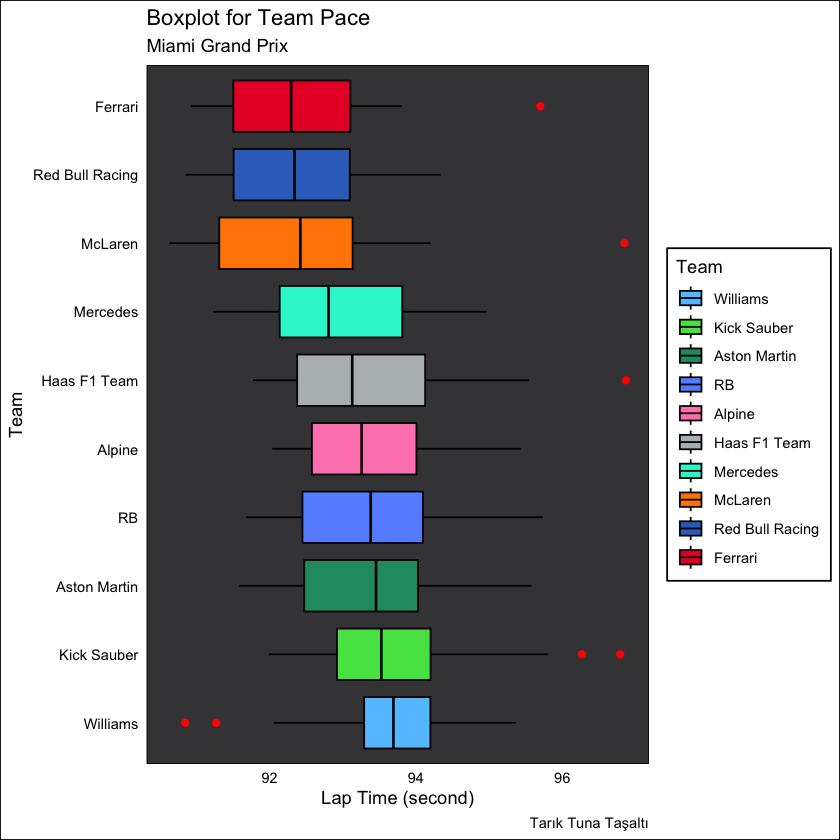

In [22]:
create_boxplot(df_quick, "Boxplot for Team Pace","Miami Grand Prix", "Team", "Lap Time (second)", quo(Team))


Takım temposu olarak bakıldığında Ferrari, Red Bull Racing ve McLaren'ın en yüksek tempoya sahip 3 takım olduğunu görmekteyiz.
Ayrıca, Williams'ın tur zamanları arasında homojenlik olduğu gözükmektedir.

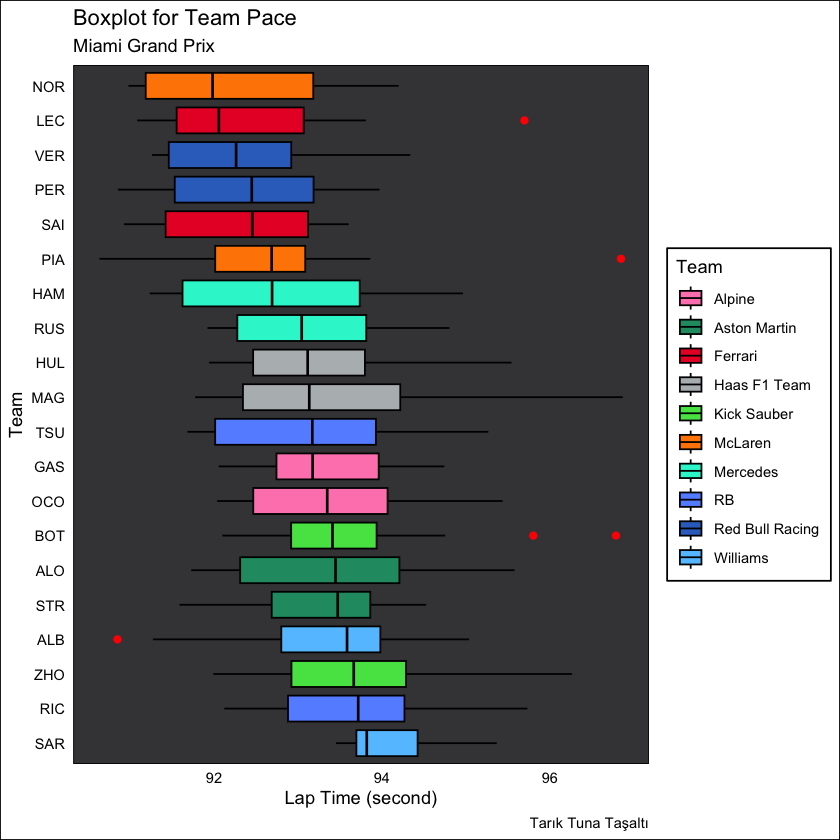

In [23]:
create_boxplot(df_quick, "Boxplot for Team Pace","Miami Grand Prix", "Team", "Lap Time (second)", quo(Driver))

Mclaren pilotu olan Norris'in en yüksek tempoya sahip olan pilot olduğu, sonrasında sırasıyla Ferrari pilotu Leclerc, sonrasında ise Red Bull Racing Pilotu Verstappen gözükmektedir. Ayrıca Sargenant'ın da daha sabit aralıklarda yavaş turlar attığı gözükmektedir.Bir önceki grafikte Williams'ın dar aralıkta olması ve Sargenant'ın bu grafikte dar aralıkta olmasının sebebi yarışa kaza sebebiyle erken veda etmesidir.

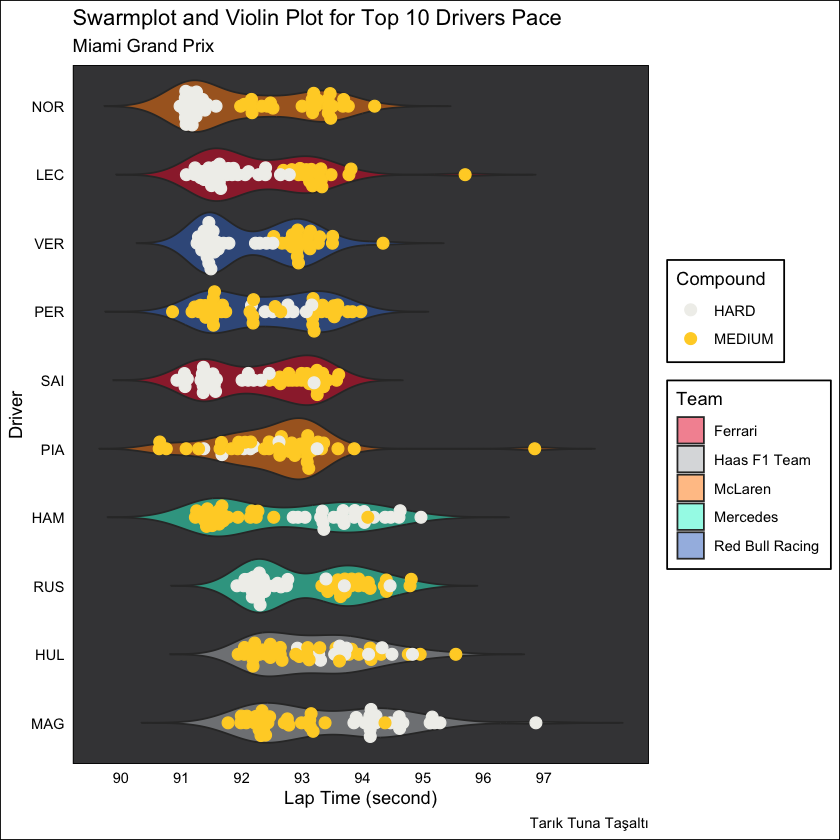

In [24]:
create_swarm_violin_plot(df_quick, "Swarmplot and Violin Plot for Top 10 Drivers Pace", "Miami Grand Prix", "Driver", "Lap Time (second)", quo(Driver), top_n_drivers = TRUE)


Swarm plota ve violin plota bakıldığında Norris, Leclerc ve Verstappen'in hard lastiklerle olan temposunun  mediumla olan temposundan daha iyi olduğu gözükmektedir.

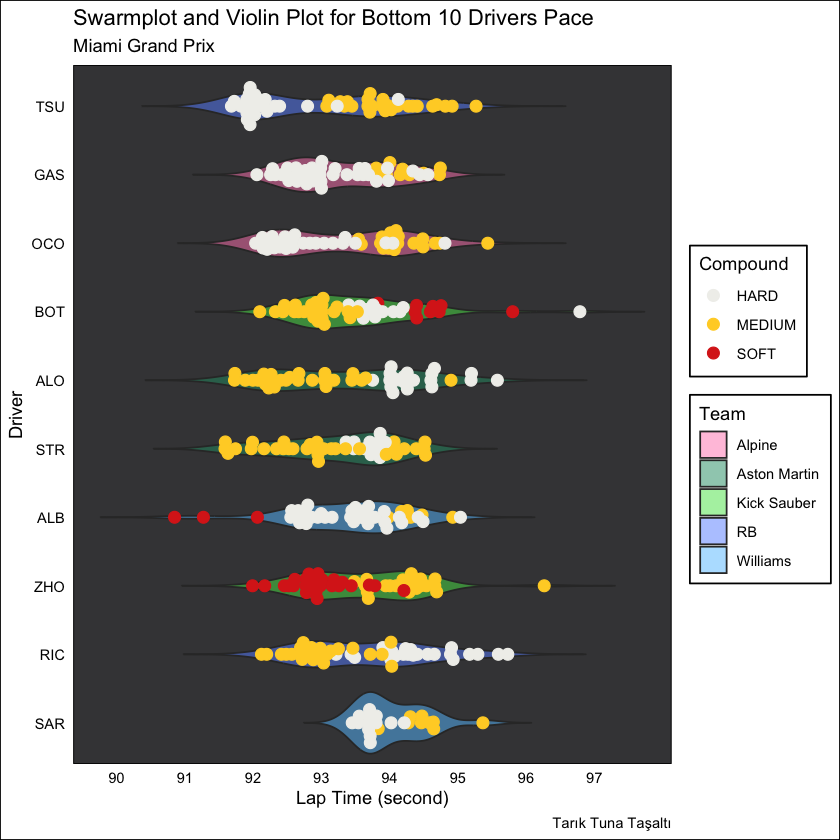

In [25]:
create_swarm_violin_plot(df_quick, "Swarmplot and Violin Plot for Bottom 10 Drivers Pace", "Miami Grand Prix", "Driver", "Lap Time (second)", quo(Driver), top_n_drivers = FALSE)


Yarışı 1. sırada bitiren Norris ve 2. sırada bitiren Verstappen'in pit stop yaptığı tur numaraları düşünüldüğünde Verstappen'in Norris'e göre daha erken pit yaptığı gözükmektedir. Norris'in pit aralığına girildiğinde çıkan güvenlik aracı Norris'e yarış boyunca büyük avantaj sağlamıştır.

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


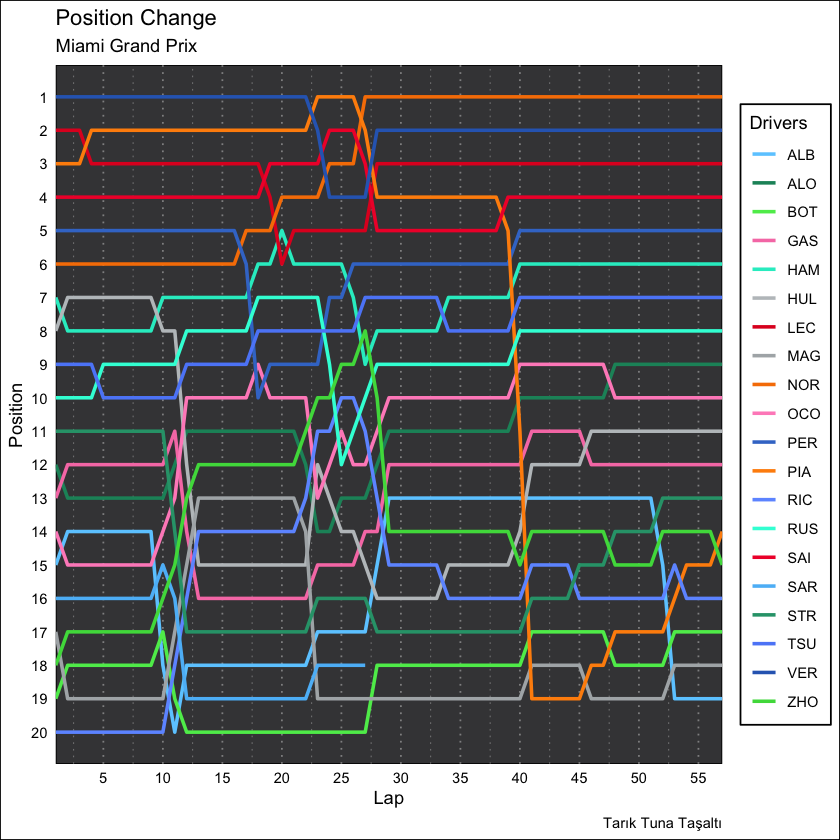

In [27]:
plot_positions(df_all, "Miami Grand Prix")

Burada pilotların yarışın kaçıncı turunda kaçıncı sırada olduğu gözükmektedir. Yarışın 27. turunda olan kaza sonucu Sargenant'ın yarışa veda ettiği gözükmektedir.

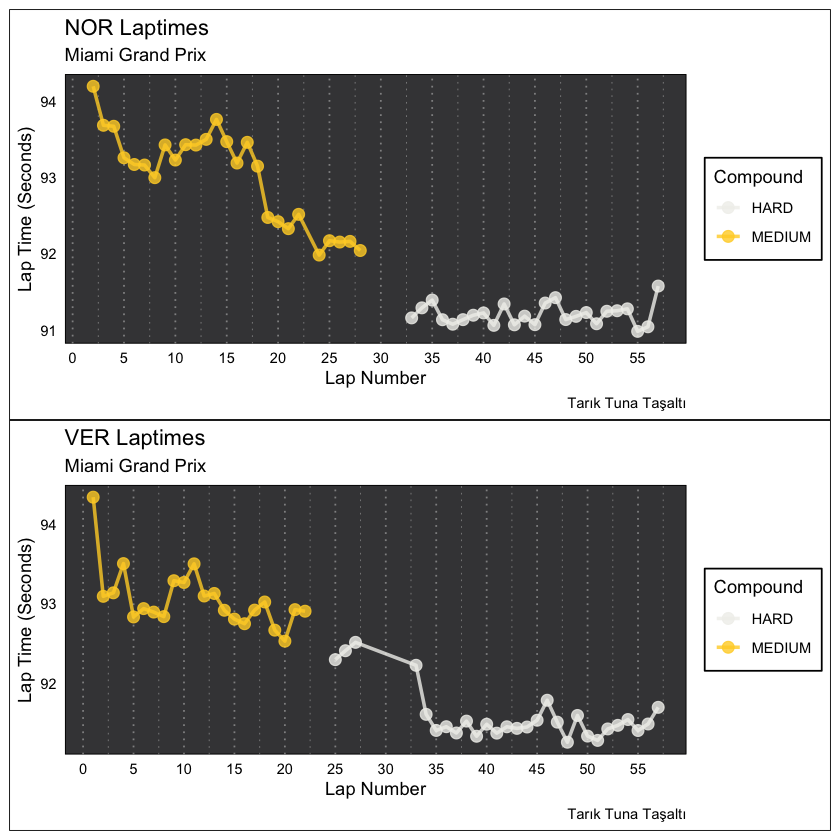

In [28]:
wrap_plots(plot_driver_laptimes(df_quick, "Miami Grand Prix", "NOR"), plot_driver_laptimes(df_quick, "Miami Grand Prix", "VER"), ncol = 1)


Bu grafikte ise Norris ile Verstappen'in tempoları kıyaslanmıştır. Verstappen ile Norris'in yarış tempolarının çok yakın olduğu ve 32. turdan itibaren ufak farkların yarışın sonucuna etki ettiği gözükmektedir.

In [29]:


race_names <- c("Bahrain Grand Prix", "Saudi Arabia Grand Prix", "Australia Grand Prix", "Japan Grand Prix", "China Grand Prix", "Miami Grand Prix", "Emilia Romagna Grand Prix")

# Veri işleme fonksiyonu
process_data <- function(file_path, race_name) {
  # Burada veri işleme işlemleri yapılacak, şimdilik boş bırakalım
  return(list(file_path = file_path, race_name = race_name))
}

# UI tanımı
ui <- fluidPage(
  titlePanel("Formula 1 Analysis"),
  sidebarLayout(
    sidebarPanel(
      selectInput("race_select", "Select Race:",
                  choices = c("Bahrain Grand Prix", "Saudi Arabia Grand Prix", "Australia Grand Prix", "Japan Grand Prix", "China Grand Prix", "Miami Grand Prix", "Emilia Romagna Grand Prix")),
      selectInput("plot_select", "Select Plot Type:",
                  choices = c("Team Boxplot", "Driver Boxplot", "Swarmplot and Violin Plot", "Strategy Plot", "Driver Position Plot", "Driver Lap Times Plot")),
      uiOutput("driver_dropdown"),  # Dinamik olarak oluşturulacak sürücü dropdown menüsü
      uiOutput("swarm_violin_select")
    ),
    mainPanel(
      fluidRow(
        column(width = 12,
               plotOutput("plot", width = "100%", height = "80vh")),
        tags$footer("Tarık Tuna Taşaltı", style = "text-align: right; padding-right: 20px;")
      )
    )
  )
)


# Server tanımı
server <- function(input, output, session) {
  data_race <- reactive({
    file_path <- if (input$plot_select == "Driver Position Plot" | input$plot_select == "Strategy Plot") {
      sprintf("2024_%02d_all.csv", match(input$race_select, race_names))
    } else {
      sprintf("2024_%02d_quick.csv", match(input$race_select, race_names))
    }
    process_data(file_path, input$race_select)
  })
  
  # Dinamik olarak sürücü dropdown menüsü oluştur
  output$driver_dropdown <- renderUI({
    if (input$plot_select == "Driver Lap Times Plot") {
      data <- read.csv(data_race()$file_path)
      unique_drivers <- unique(data$Driver)
      selectInput("driver_select", "Select Driver:", choices = unique_drivers)
    }
  })
  
  # Dinamik olarak Swarmplot ve Violin Plot alt menüsü oluştur
  output$swarm_violin_select <- renderUI({
    if (input$plot_select == "Swarmplot and Violin Plot") {
      selectInput("swarm_violin_select", "Select Top/Bottom 10 Drivers:",
                  choices = c("Top 10", "Bottom 10"))
    }
  })
  
  outputOptions(output, "swarm_violin_select", suspendWhenHidden = FALSE)
  
  output$plot <- renderPlot({
    data <- read.csv(data_race()$file_path)
    race_name <- data_race()$race_name
    
    if (input$plot_select == "Team Boxplot") {
      create_boxplot(data, "Boxplot for Team Pace", race_name, "Team", "Lap Time (second)", quo(Team))
    } else if (input$plot_select == "Driver Boxplot") {
      create_boxplot(data, "Boxplot for Driver Pace", race_name, "Driver", "Lap Time (second)", quo(Driver), show_legend = TRUE)
    } else if (input$plot_select == "Swarmplot and Violin Plot") {
      if (!is.null(input$swarm_violin_select)) {
        if (input$swarm_violin_select == "Top 10") {
          create_swarm_violin_plot(data, "Swarmplot and Violin Plot for Top 10 Drivers Pace", race_name, "Driver", "Lap Time (second)", quo(Driver), top_n_drivers = TRUE)
        } else if (input$swarm_violin_select == "Bottom 10") {
          create_swarm_violin_plot(data, "Swarmplot and Violin Plot for Bottom 10 Drivers Pace", race_name, "Driver" ,"Lap Time (second)", quo(Driver), top_n_drivers = FALSE)
        }
      }
    } else if (input$plot_select == "Strategy Plot") {
      plot_strategy(data, race_name)
    } else if (input$plot_select == "Driver Position Plot") {
      plot_positions(data, race_name)
    } else if (input$plot_select == "Driver Lap Times Plot") {
      selected_driver <- input$driver_select
      plot_driver_laptimes(data, race_name, selected_driver)
    }
  })
}

# Uygulamayı başlat
shinyApp(ui = ui, server = server)



Listening on http://127.0.0.1:4762

Warning message:
“Error in plot_strategy: 'black' nesnesi bulunamadı”
Warning message:
“Error in plot_strategy: 'black' nesnesi bulunamadı”
Warning message:
“Error in plot_strategy: 'black' nesnesi bulunamadı”
Warning message:
“Error in filter: ℹ In argument: `Driver == driver_name`.
Caused by error:
! `..1` must be of size 810 or 1, not size 0.”
Input to asJSON(keep_vec_names=TRUE) is a named vector. In a future version of jsonlite, this option will not be supported, and named vectors will be translated into arrays instead of objects. If you want JSON object output, please use a named list instead. See ?toJSON.

Warning message:
“Error in plot_strategy: 'black' nesnesi bulunamadı”


Bu kod bloğu çalıştırılarak istenen yarışın istenen grafiği User Interface şeklinde gösterilmektedir.